# Advanced Data Visualization

### Introduction to Plotly

Plotly is a powerful, interactive charting library that allows you to build beautiful, publication-quality graphs directly within Python. Unlike static plotting libraries like Matplotlib or Seaborn, Plotly charts are fully interactive by default—allowing users to hover over data points for tooltips, zoom in on specific regions, pan across plots, and toggle individual categories or traces on and off using the chart's legend. In this section, we set up our workspace, import core visualization libraries, and generate a simulated sales dataset to power our explorations.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

# Generate a toy dataset containing 100 samples
np.random.seed(42)

countries = {
    'Vietnam': ('VNM', 14.0583, 108.2772),
    'Thailand': ('THA', 15.8700, 100.9925),
    'Japan': ('JPN', 36.2048, 138.2529),
    'South Korea': ('KOR', 35.9078, 127.7669),
    'Singapore': ('SGP', 1.3521, 103.8198),
    'Malaysia': ('MYS', 4.2105, 101.9758),
    'Indonesia': ('IDN', -0.7893, 113.9213),
    'Australia': ('AUS', -25.2744, 133.7751),
    'India': ('IND', 20.5937, 78.9629),
    'Philippines': ('PHL', 12.8797, 121.7740)
}

country_names = list(countries.keys())

df = pd.DataFrame({
    'Date': pd.date_range('2026-01-01', periods=100, freq='D'),
    'Country': np.random.choice(country_names, 100),
    'Category': np.random.choice(
        ['Electronics', 'Clothing', 'Food', 'Furniture'], 100
    ),
    'Revenue': np.random.randint(100, 2000, 100),
    'Profit': np.random.randint(20, 500, 100),
    'Satisfaction': np.random.randint(1, 6, 100),
    'Units_Sold': np.random.randint(1, 50, 100)
})

df['Country_Code'] = df['Country'].map(
    lambda x: countries[x][0]
)
df['Latitude'] = df['Country'].map(
    lambda x: countries[x][1]
)
df['Longitude'] = df['Country'].map(
    lambda x: countries[x][2]
)

# Add some variation to coordinates so points are distinguishable
df['Latitude'] += np.random.uniform(-0.5, 0.5, 100)
df['Longitude'] += np.random.uniform(-0.5, 0.5, 100)

# Calculate profit margin
df['Profit_Margin'] = df['Profit'] / df['Revenue'] * 100

df.head()

,Date,Country,Category,Revenue,Profit,Satisfaction,Units_Sold,Country_Code,Latitude,Longitude,Profit_Margin
0,2026-01-01,Indonesia,Furniture,1348,131,5,22,IDN,-0.917282,113.698681,9.718101
1,2026-01-02,South Korea,Clothing,1942,79,3,29,KOR,36.184213,127.455021,4.067971
2,2026-01-03,Australia,Electronics,1357,388,4,3,AUS,-25.433596,133.738798,28.592483
3,2026-01-04,Singapore,Furniture,783,21,1,12,SGP,1.782857,103.673152,2.681992
4,2026-01-05,Indonesia,Food,763,404,5,26,IDN,-0.430887,114.004956,52.948886


### Interactive Visualization

In this section, we leverage **Plotly Express (`px`)** to build highly customizable and interactive scatter and bar charts. These visualizations allow us to drill down into our product categories, inspect the relationship between operational metrics (like Revenue and Profit), and gain a granular understanding of how sales volumes scale across different segments using bubble sizes.

In [3]:
fig = px.scatter(
    df,
    x='Revenue',
    y='Profit',
    color='Category',
    size='Units_Sold',
    hover_data=['Country', 'Date', 'Satisfaction'],
    title='Revenue and Profit by Product Category'
)

fig.show()

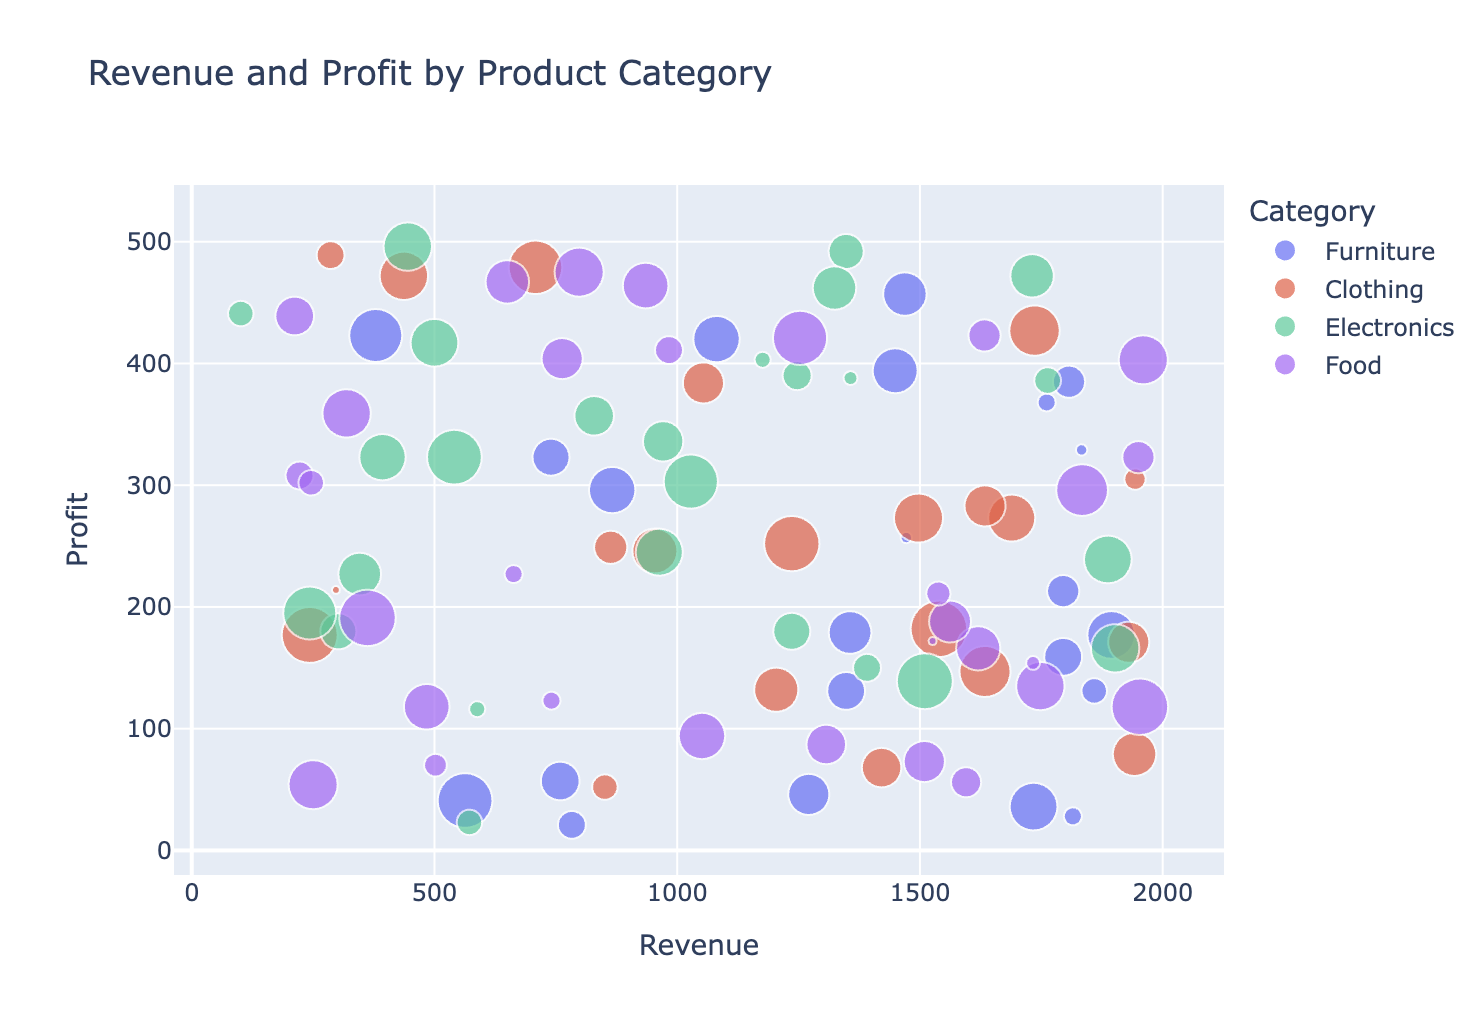

In [4]:
fig = px.bar(
    df,
    x='Category',
    y='Revenue',
    color='Category',
    hover_data=['Profit', 'Units_Sold'],
    title='Revenue by Product Category'
)

fig.show()

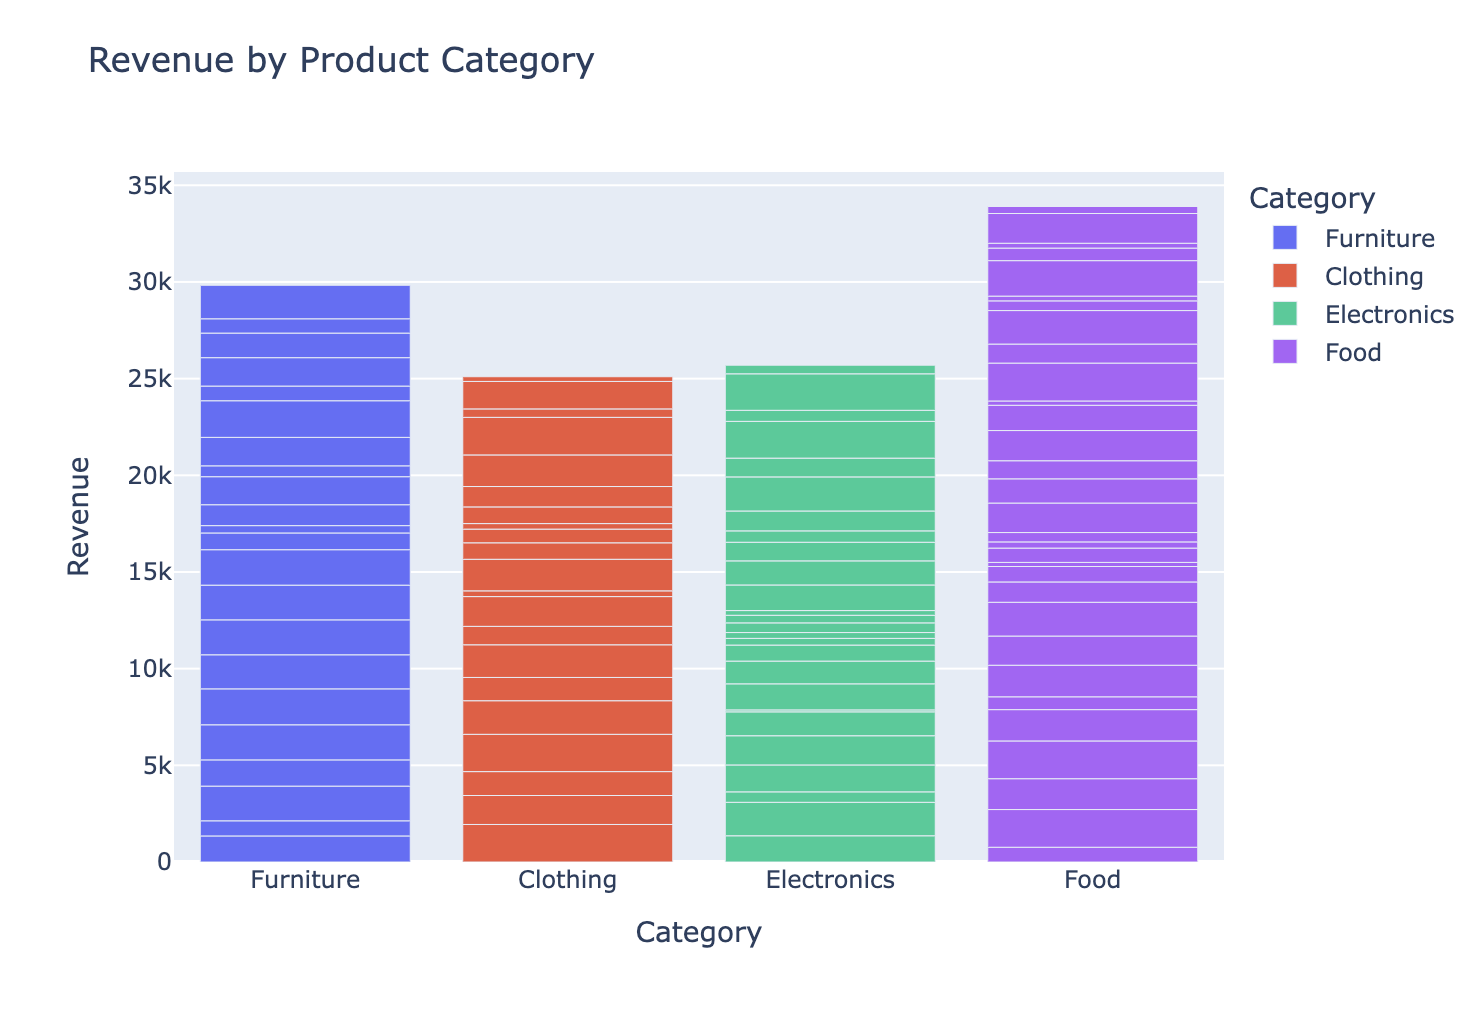

In [5]:
category_sales = df.groupby(
    'Category', as_index=False
)['Revenue'].sum()

fig = px.bar(
    category_sales,
    x='Category',
    y='Revenue',
    color='Category',
    title='Total Revenue by Category'
)

fig.show()

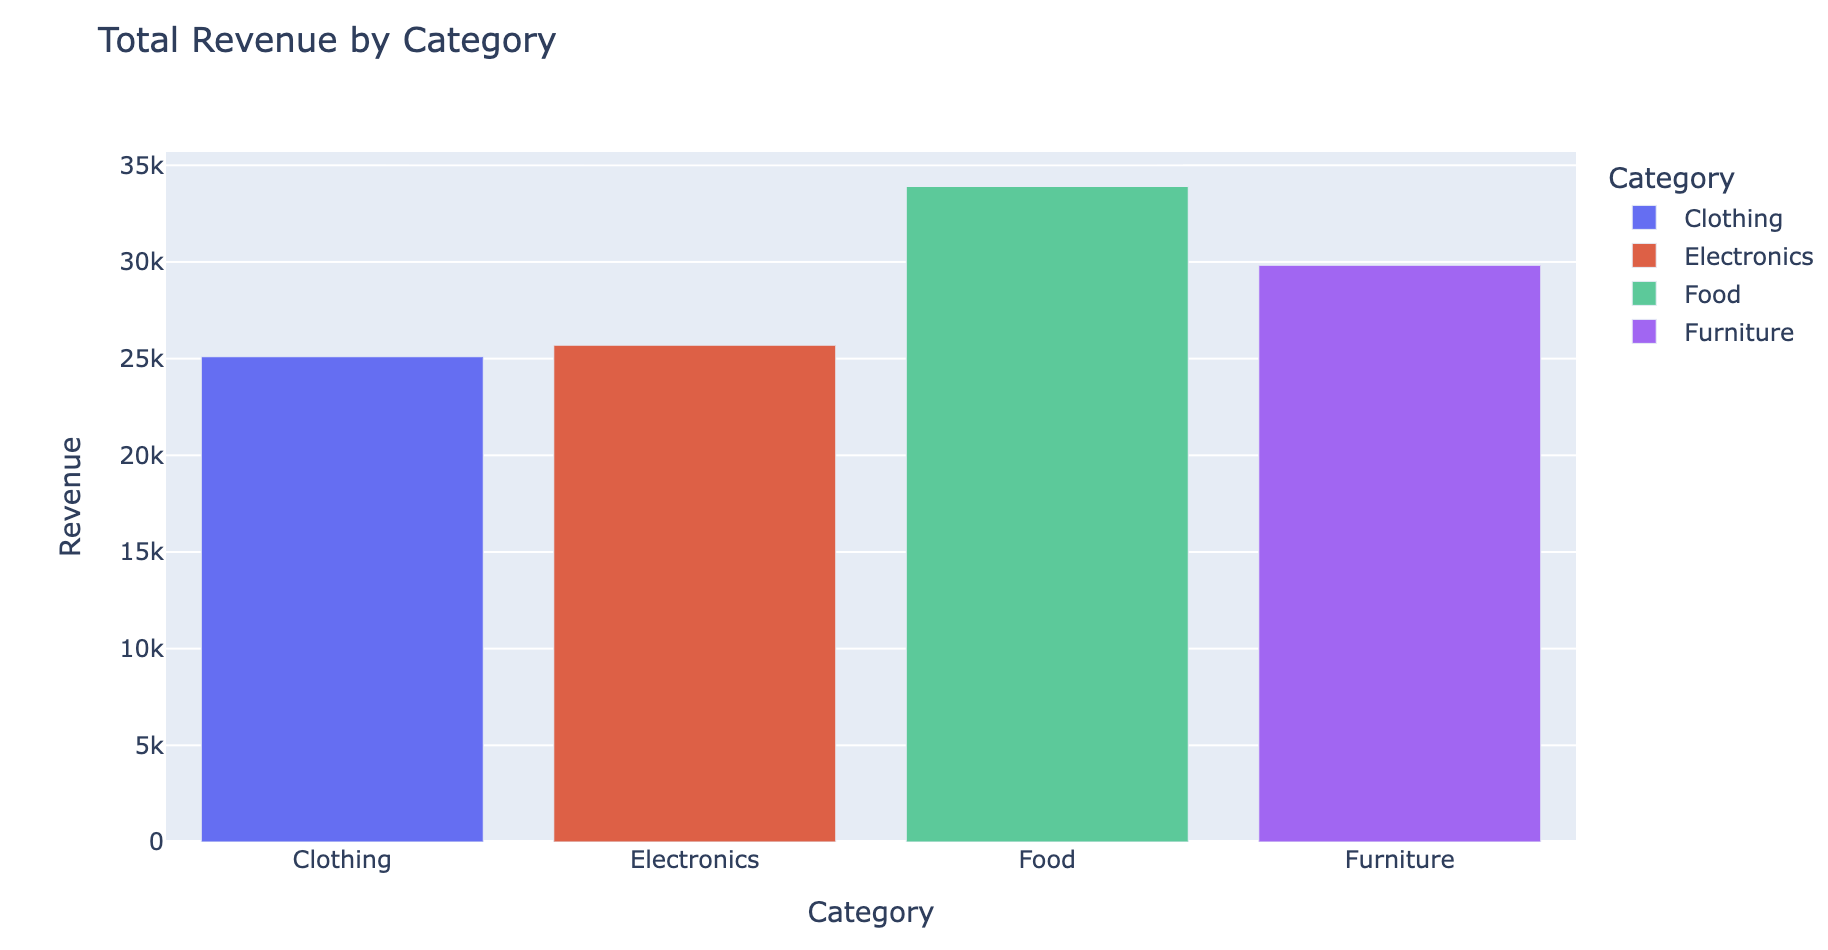

## Geospatial Visualization

Geospatial visualizations are critical when dealing with international or regional operations. By mapping revenue and sales metrics directly to geographic boundaries (Choropleth maps) or coordinates (Scatter Geo plots), we can rapidly pinpoint underperforming regions, identify geographic hubs of high profitability, and visually grasp the physical distribution of our target audience across countries.

In [6]:
country_sales = df.groupby(
    ['Country', 'Country_Code'], as_index=False
).agg(
    Revenue=('Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Units_Sold', 'sum')
)

country_sales

,Country,Country_Code,Revenue,Profit,Units_Sold
0,Australia,AUS,17187,4749,313
1,India,IND,13320,2483,358
2,Indonesia,IDN,14785,2570,255
3,Japan,JPN,10120,2514,300
4,Malaysia,MYS,9339,1728,140
5,Philippines,PHL,12690,2509,218
6,Singapore,SGP,12011,1900,289
7,South Korea,KOR,8794,3234,268
8,Thailand,THA,11651,2665,227
9,Vietnam,VNM,4626,1454,153


In [7]:
fig = px.choropleth(
    country_sales,
    locations='Country_Code',
    locationmode='ISO-3',
    color='Revenue',
    hover_name='Country',
    hover_data=['Profit', 'Units_Sold'],
    color_continuous_scale='Viridis',
    title='Total Revenue by Country'
)

fig.show()

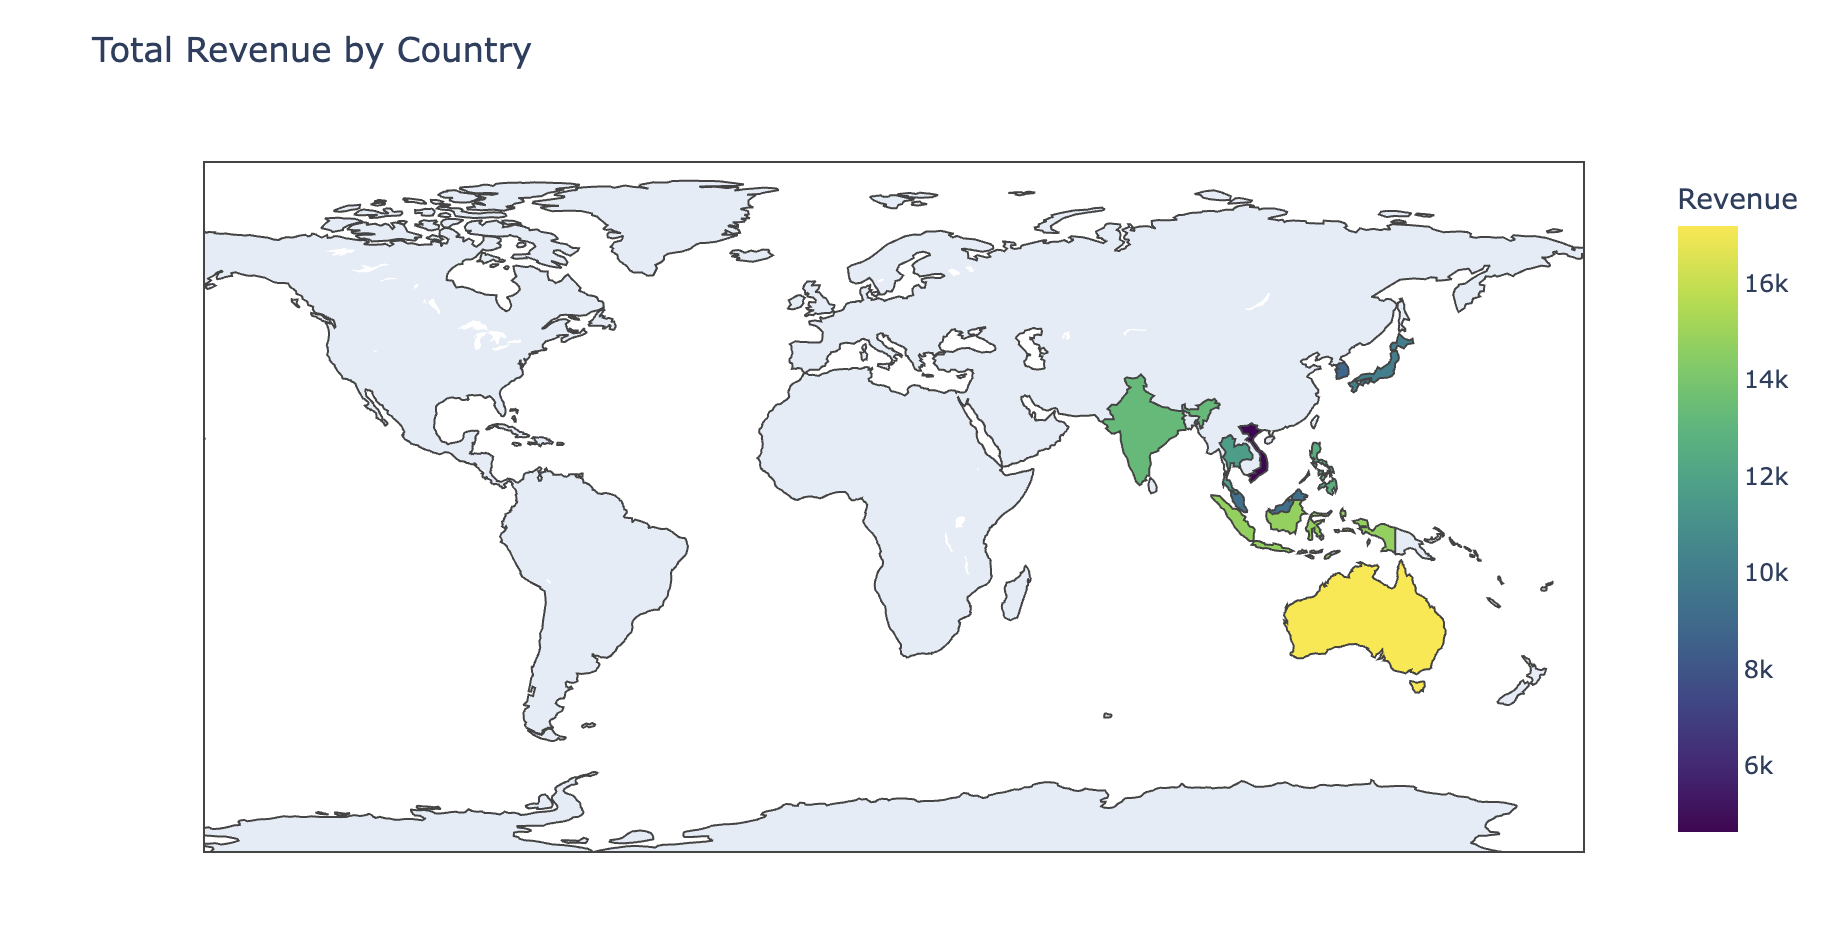

In [8]:
fig = px.scatter_geo(
    df,
    lat='Latitude',
    lon='Longitude',
    color='Category',
    size='Revenue',
    hover_name='Country',
    hover_data=['Revenue', 'Profit'],
    title='Geographic Distribution of Sales'
)

fig.show()

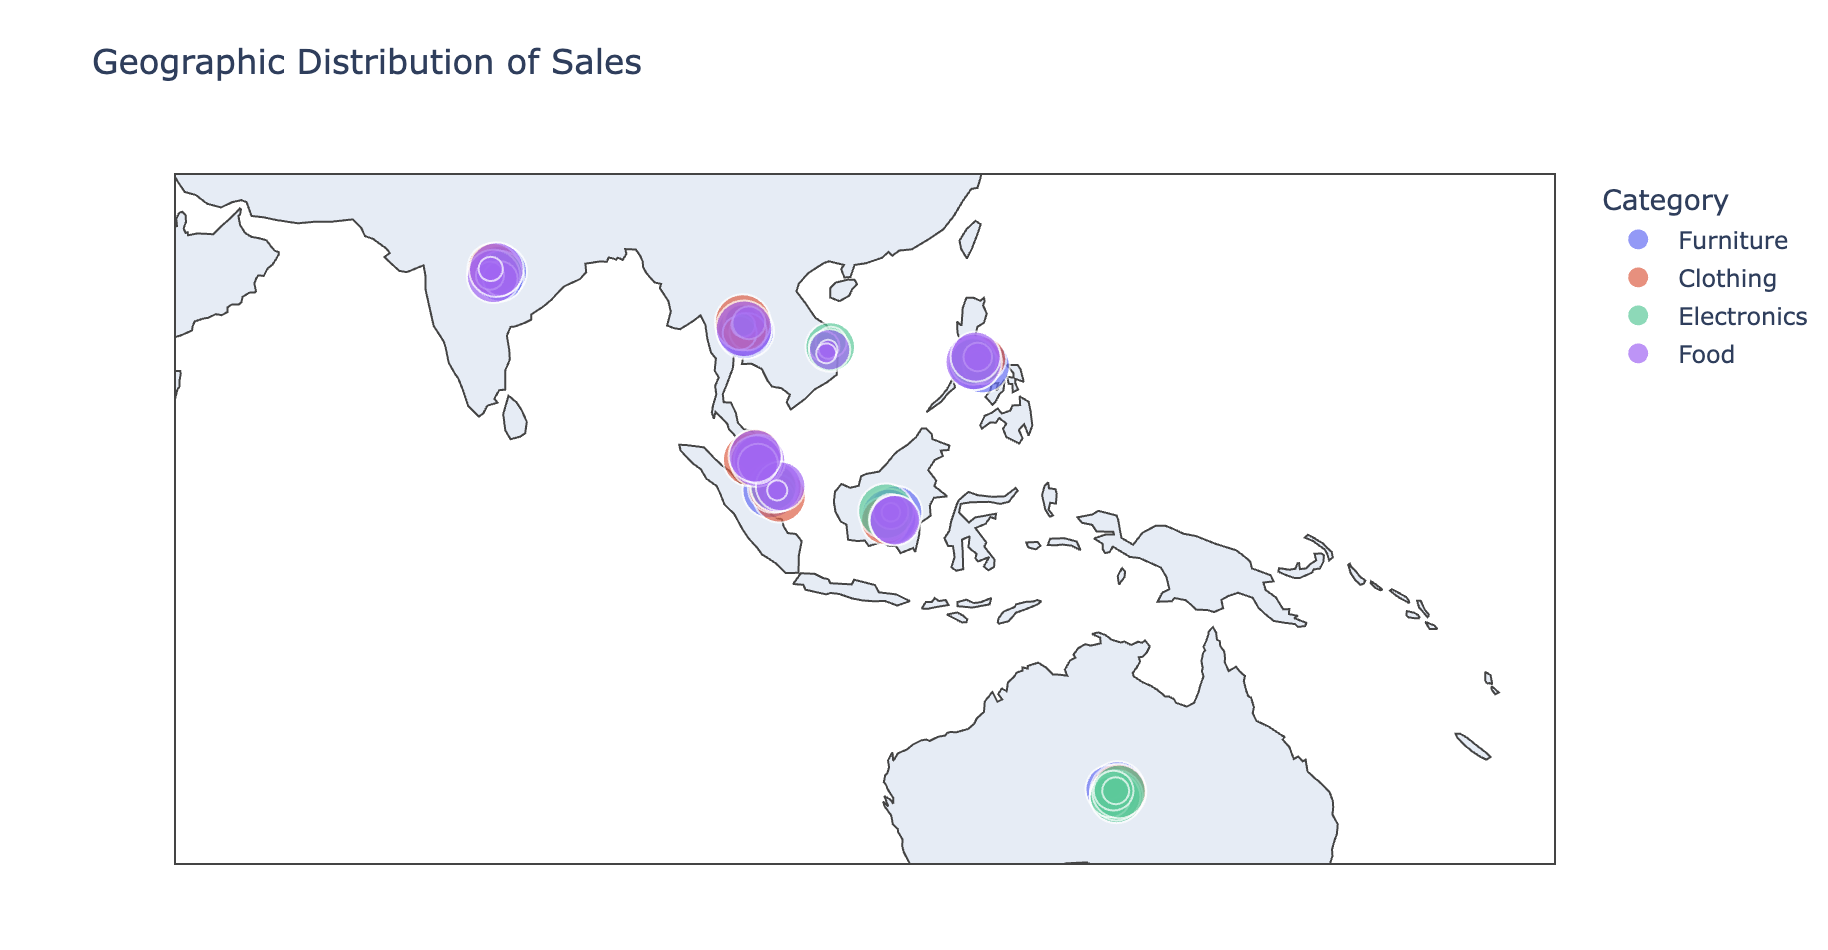

## Time-Series Visualization

Analyzing business performance over time reveals trends, cyclical patterns, and seasonality. Here, we track daily revenue and calculate a **7-Day Moving Average** to smooth out daily fluctuations. This helps us distinguish minor, short-term noise from long-term upward or downward trends in our sales operations.

In [9]:
daily_sales = df.groupby(
    'Date', as_index=False
)['Revenue'].sum()

fig = px.line(
    daily_sales,
    x='Date',
    y='Revenue',
    markers=True,
    title='Daily Revenue Over Time'
)

fig.show()

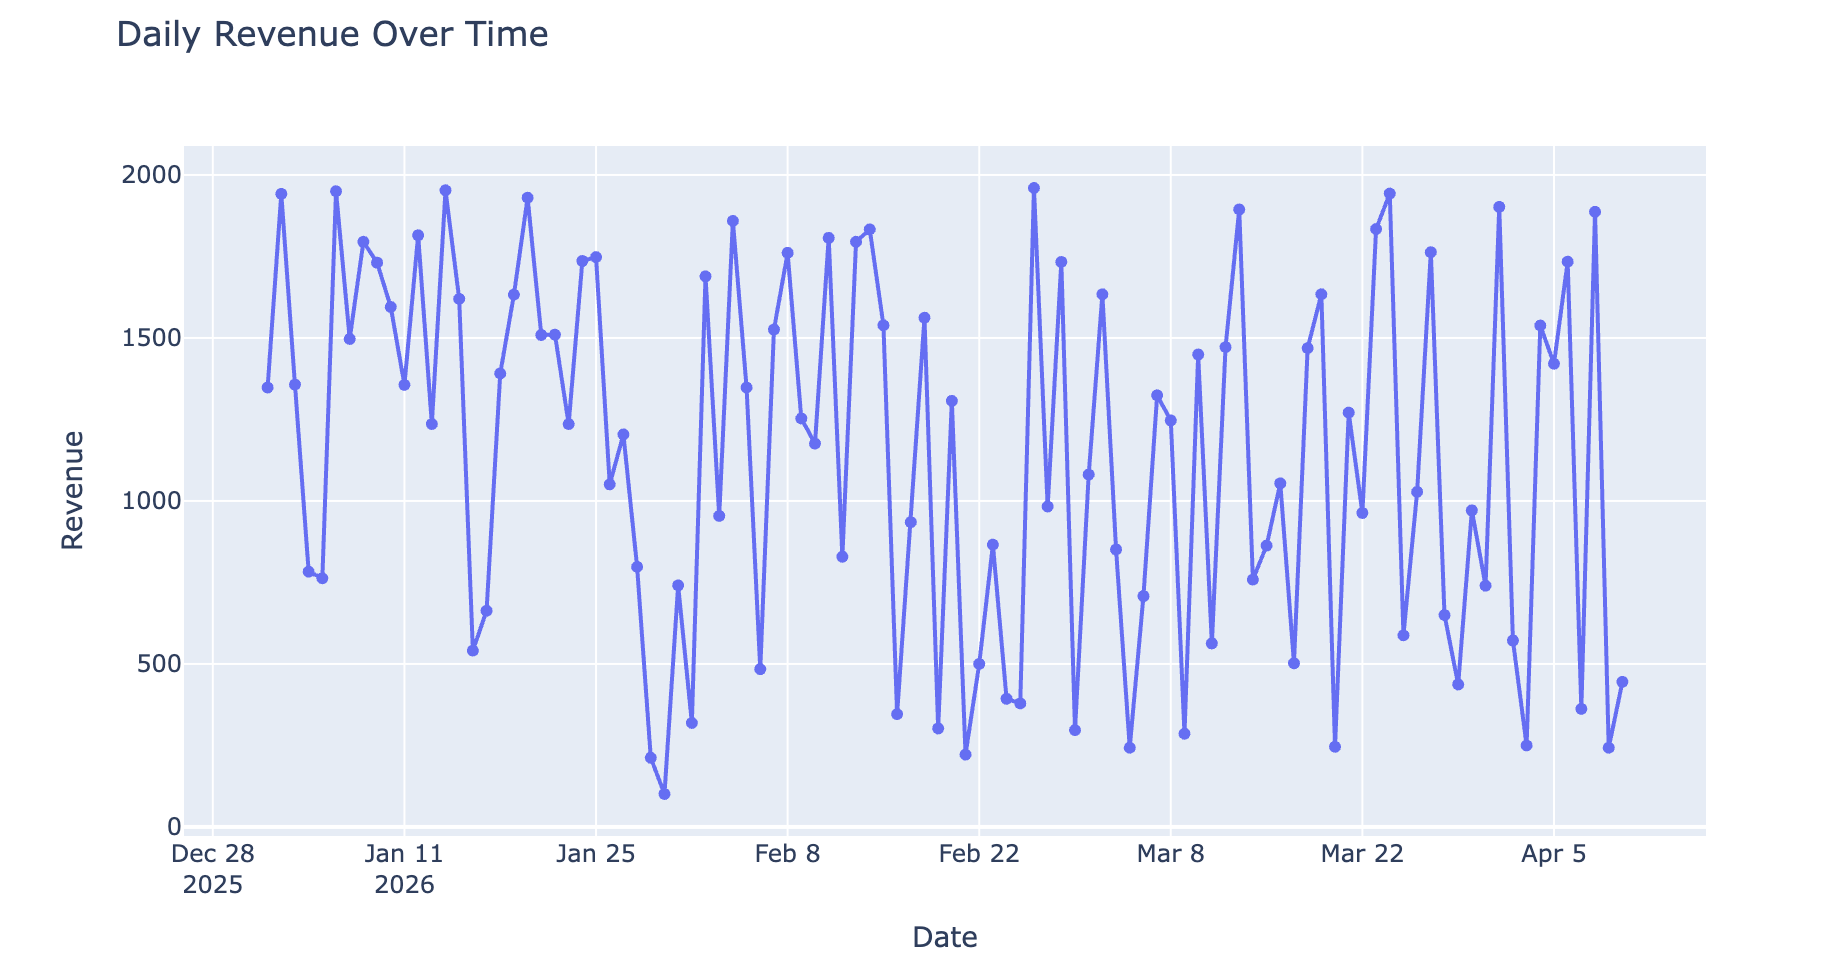

In [10]:
daily_sales['Moving_Average'] = (
    daily_sales['Revenue']
    .rolling(window=7, min_periods=1)
    .mean()
)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=daily_sales['Date'],
    y=daily_sales['Revenue'],
    mode='lines',
    name='Daily Revenue'
))

fig.add_trace(go.Scatter(
    x=daily_sales['Date'],
    y=daily_sales['Moving_Average'],
    mode='lines',
    name='7-Day Moving Average'
))

fig.update_layout(
    title='Daily Revenue and Moving Average',
    xaxis_title='Date',
    yaxis_title='Revenue'
)

fig.show()

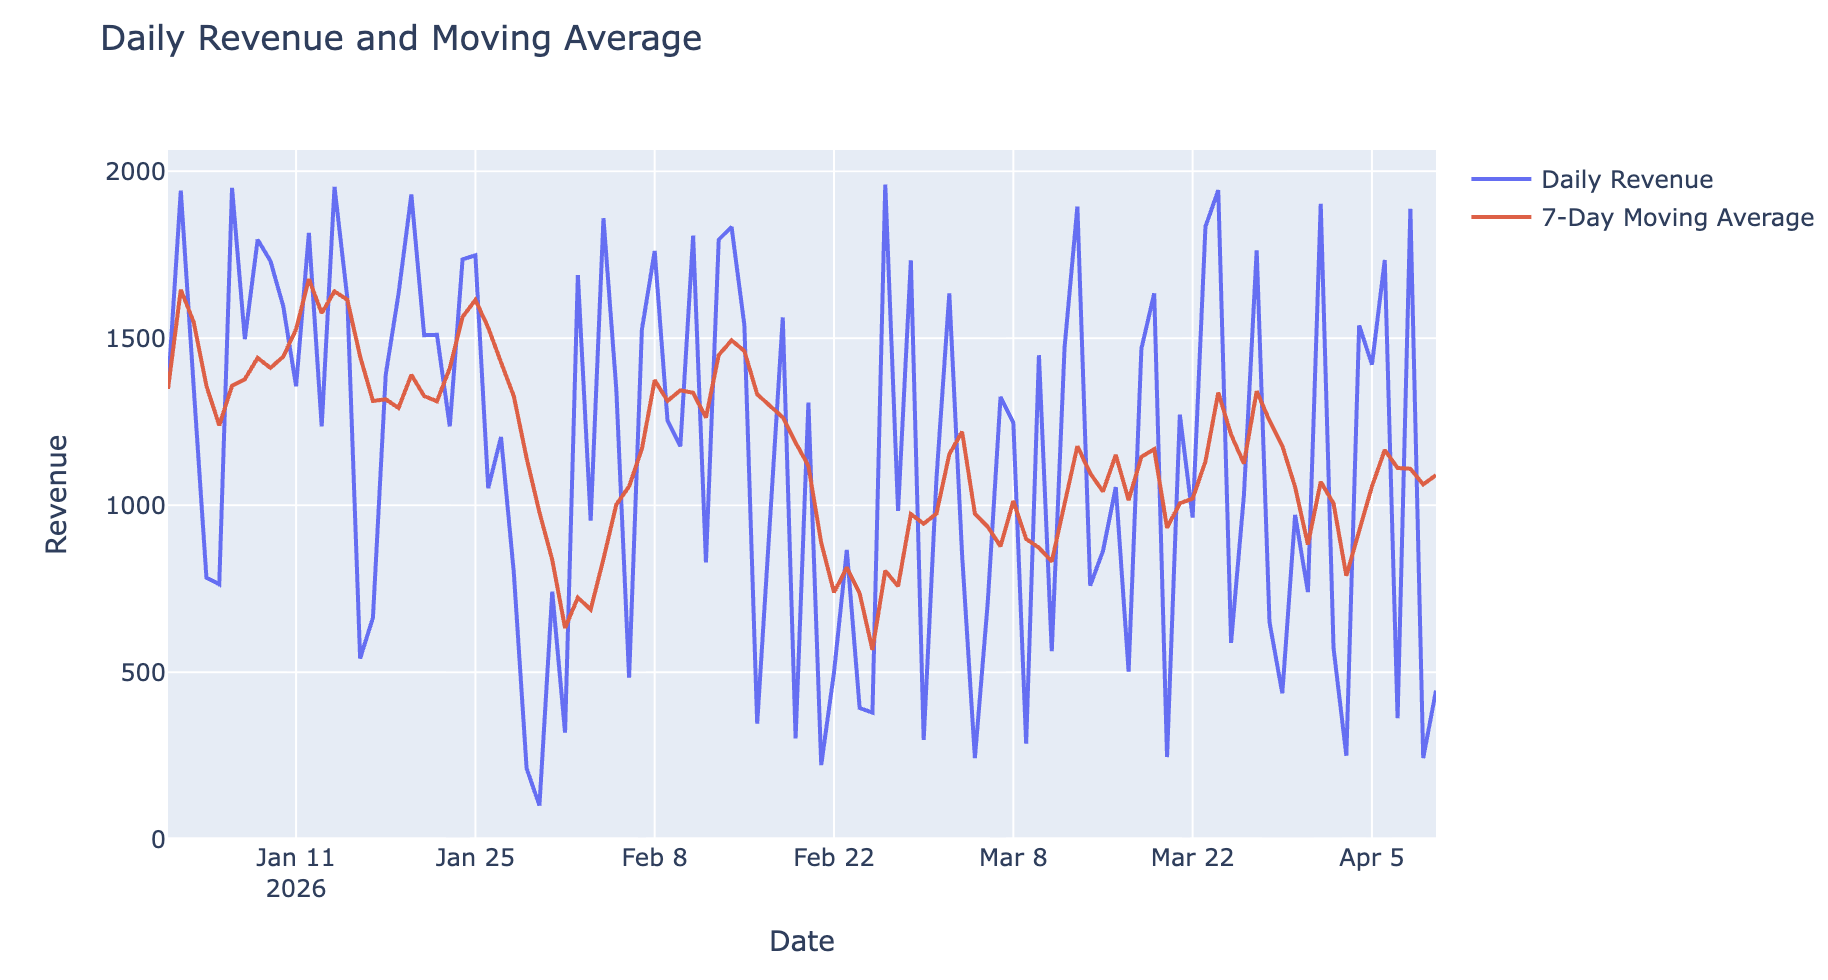

## Network Visualization

Network graphs are ideal for mapping relationships, hierarchies, or associations between discrete entities. In this example, we use the `networkx` library to compute a spring layout topology and Plotly to render it, visually connecting specific retail products to their parent product categories.

In [11]:
import networkx as nx

G = nx.Graph()

# Add category nodes
categories = ['Electronics', 'Clothing', 'Food', 'Furniture']
G.add_nodes_from(categories, node_type='Category')

# Add product nodes and their category connections
products = {
    'Laptop': 'Electronics',
    'Phone': 'Electronics',
    'Shirt': 'Clothing',
    'Jacket': 'Clothing',
    'Coffee': 'Food',
    'Bread': 'Food',
    'Chair': 'Furniture',
    'Desk': 'Furniture'
}

for product, category in products.items():
    G.add_node(product, node_type='Product')
    G.add_edge(product, category)

# Calculate node positions
pos = nx.spring_layout(G, seed=42)

# Create edge coordinates
edge_x, edge_y = [], []

for start, end in G.edges():
    x0, y0 = pos[start]
    x1, y1 = pos[end]

    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x,
    y=edge_y,
    mode='lines',
    line=dict(width=1, color='gray'),
    hoverinfo='none'
)

# Create node coordinates and labels
node_x, node_y, node_text, node_colors = [], [], [], []

for node in G.nodes():
    x, y = pos[node]

    node_x.append(x)
    node_y.append(y)
    node_text.append(node)
    node_colors.append(G.nodes[node]['node_type'])

node_trace = go.Scatter(
    x=node_x,
    y=node_y,
    mode='markers+text',
    text=node_text,
    textposition='top center',
    hovertext=node_text,
    hoverinfo='text',
    marker=dict(
        size=20,
        color=[
            'royalblue' if t == 'Category' else 'orange'
            for t in node_colors
        ]
    )
)

fig = go.Figure(data=[edge_trace, node_trace])

fig.update_layout(
    title='Product and Category Network',
    showlegend=False,
    xaxis=dict(visible=False),
    yaxis=dict(visible=False)
)

fig.show()

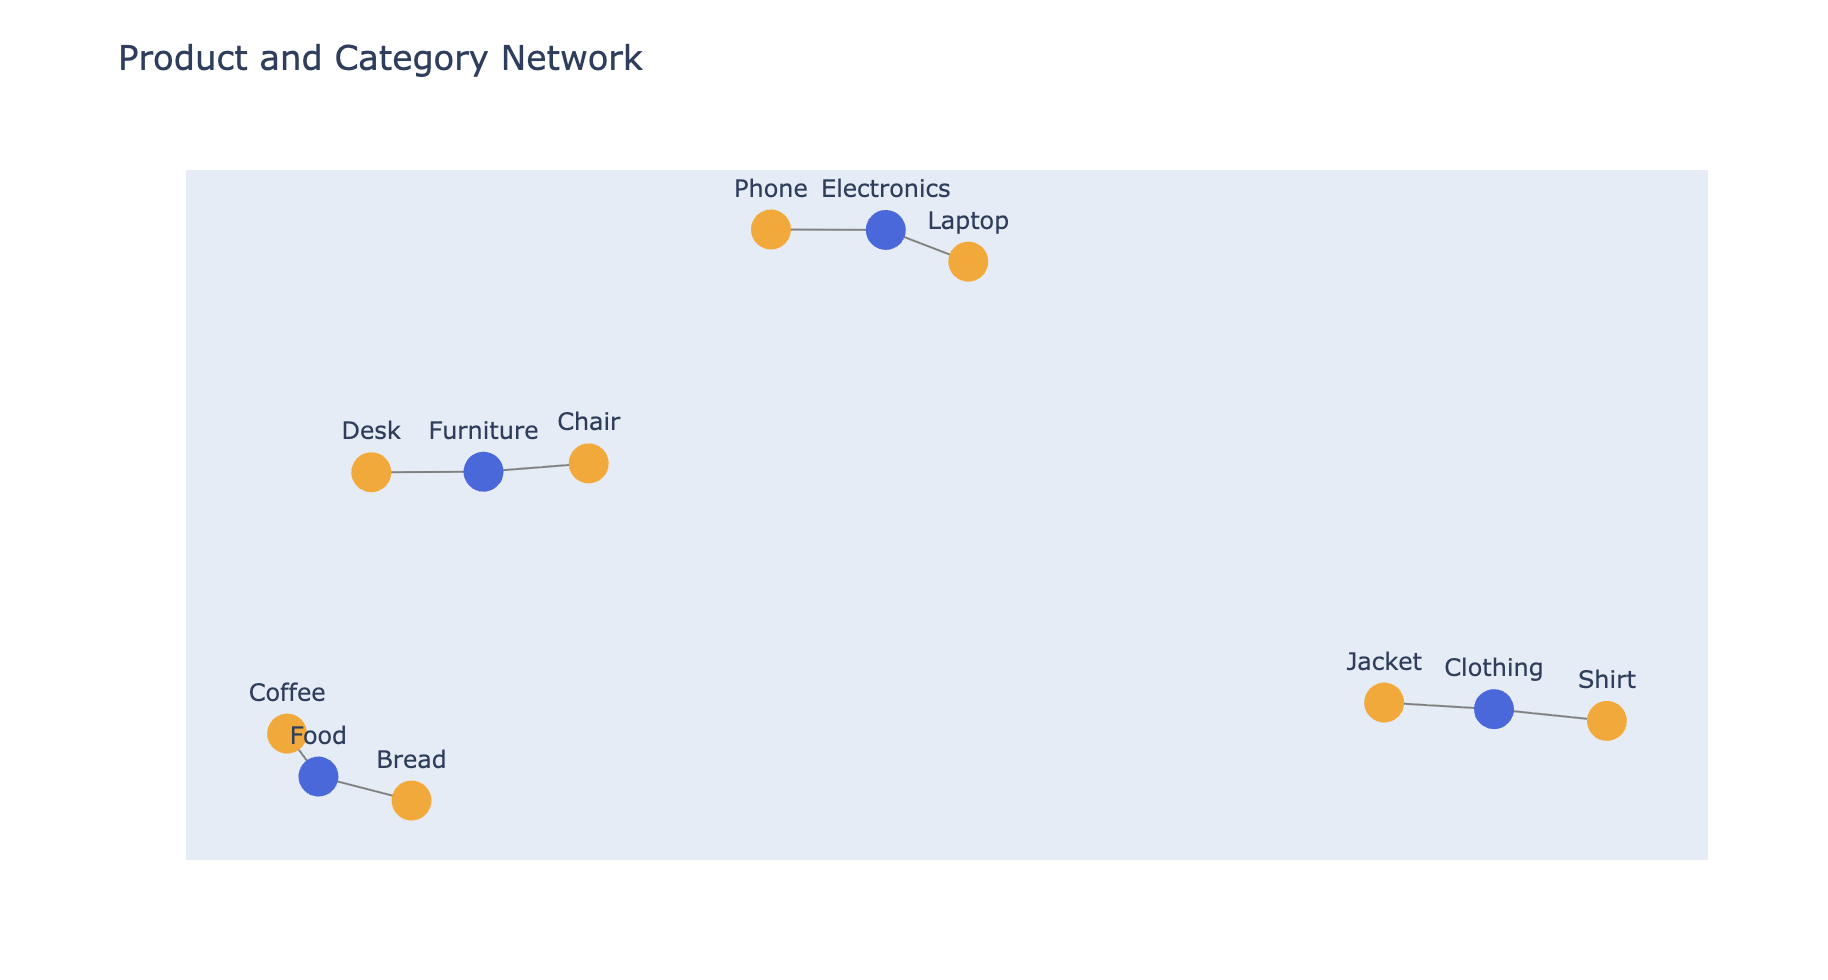

## Multivariate Visualization

Multivariate analysis involves observing more than two variables simultaneously to see how they interact. By mapping metrics to spatial axes (X and Y), marker sizes, color scales, and symbol styles, we compress five dimensions of data into a single 2D scatter plot. We supplement this with a Pearson Correlation Heatmap to identify statistical relationships.

In [12]:
fig = px.scatter(
    df,
    x='Revenue',
    y='Profit',
    size='Units_Sold',
    color='Satisfaction',
    symbol='Category',
    hover_name='Country',
    hover_data=['Date', 'Profit_Margin'],
    color_continuous_scale='Plasma',
    title='Multivariate Sales Analysis'
)

fig.show()

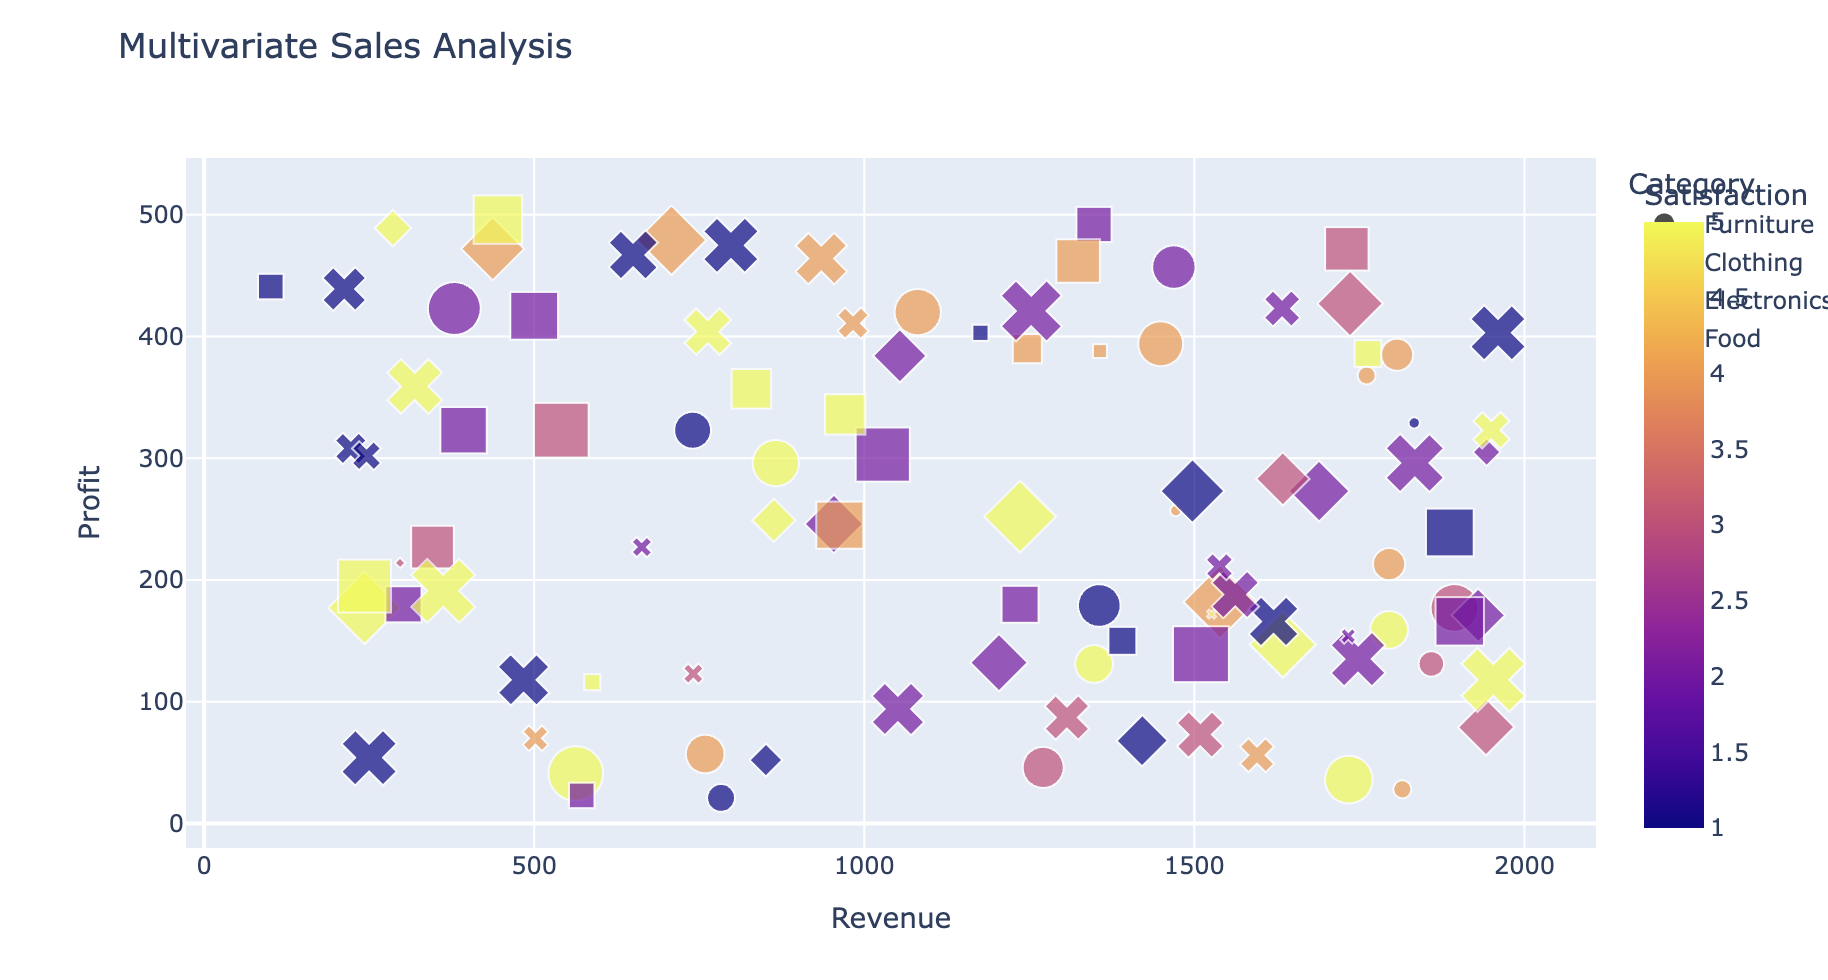

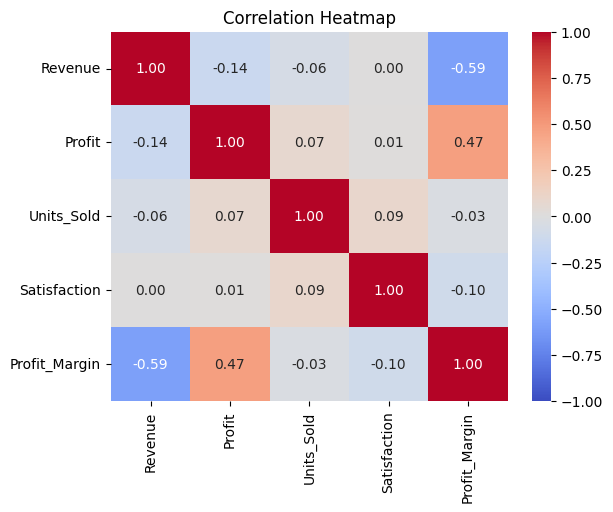

In [13]:
numeric_df = df[
    ['Revenue', 'Profit', 'Units_Sold',
     'Satisfaction', 'Profit_Margin']
]

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

## Real-Time Dashboard

This section demonstrates how to combine multiple distinct visualizations into a unified, consolidated view. By utilizing Plotly's `make_subplots`, we layout categorical revenue, scatter patterns, temporal trends, and key performance indicator (KPI) metric cards on a single canvas, mimicking an executive-level monitoring panel.

In [14]:
from plotly.subplots import make_subplots

category_sales = df.groupby(
    'Category', as_index=False
)['Revenue'].sum()

daily_sales = df.groupby(
    'Date', as_index=False
)['Revenue'].sum()

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        'Revenue by Category',
        'Revenue vs. Profit',
        'Daily Revenue',
        'Key Performance Indicators'
    ),
    specs=[
        [{}, {}],
        [{}, {'type': 'indicator'}]
    ]
)

# 1. Revenue by category
fig.add_trace(
    go.Bar(
        x=category_sales['Category'],
        y=category_sales['Revenue'],
        name='Revenue'
    ),
    row=1, col=1
)

# 2. Revenue vs. profit
fig.add_trace(
    go.Scatter(
        x=df['Revenue'],
        y=df['Profit'],
        mode='markers',
        name='Sales Records',
        text=df['Country'],
        hovertemplate=(
            'Country: %{text}<br>'
            'Revenue: %{x}<br>'
            'Profit: %{y}<extra></extra>'
        )
    ),
    row=1, col=2
)

# 3. Daily revenue
fig.add_trace(
    go.Scatter(
        x=daily_sales['Date'],
        y=daily_sales['Revenue'],
        mode='lines',
        name='Daily Revenue'
    ),
    row=2, col=1
)

# 4. Total revenue indicator
total_revenue = df['Revenue'].sum()

fig.add_trace(
    go.Indicator(
        mode='number',
        value=total_revenue,
        title={'text': 'Total Revenue'}
    ),
    row=2, col=2
)

fig.update_layout(
    title='Sales Performance Dashboard',
    height=700,
    showlegend=False
)

fig.show()

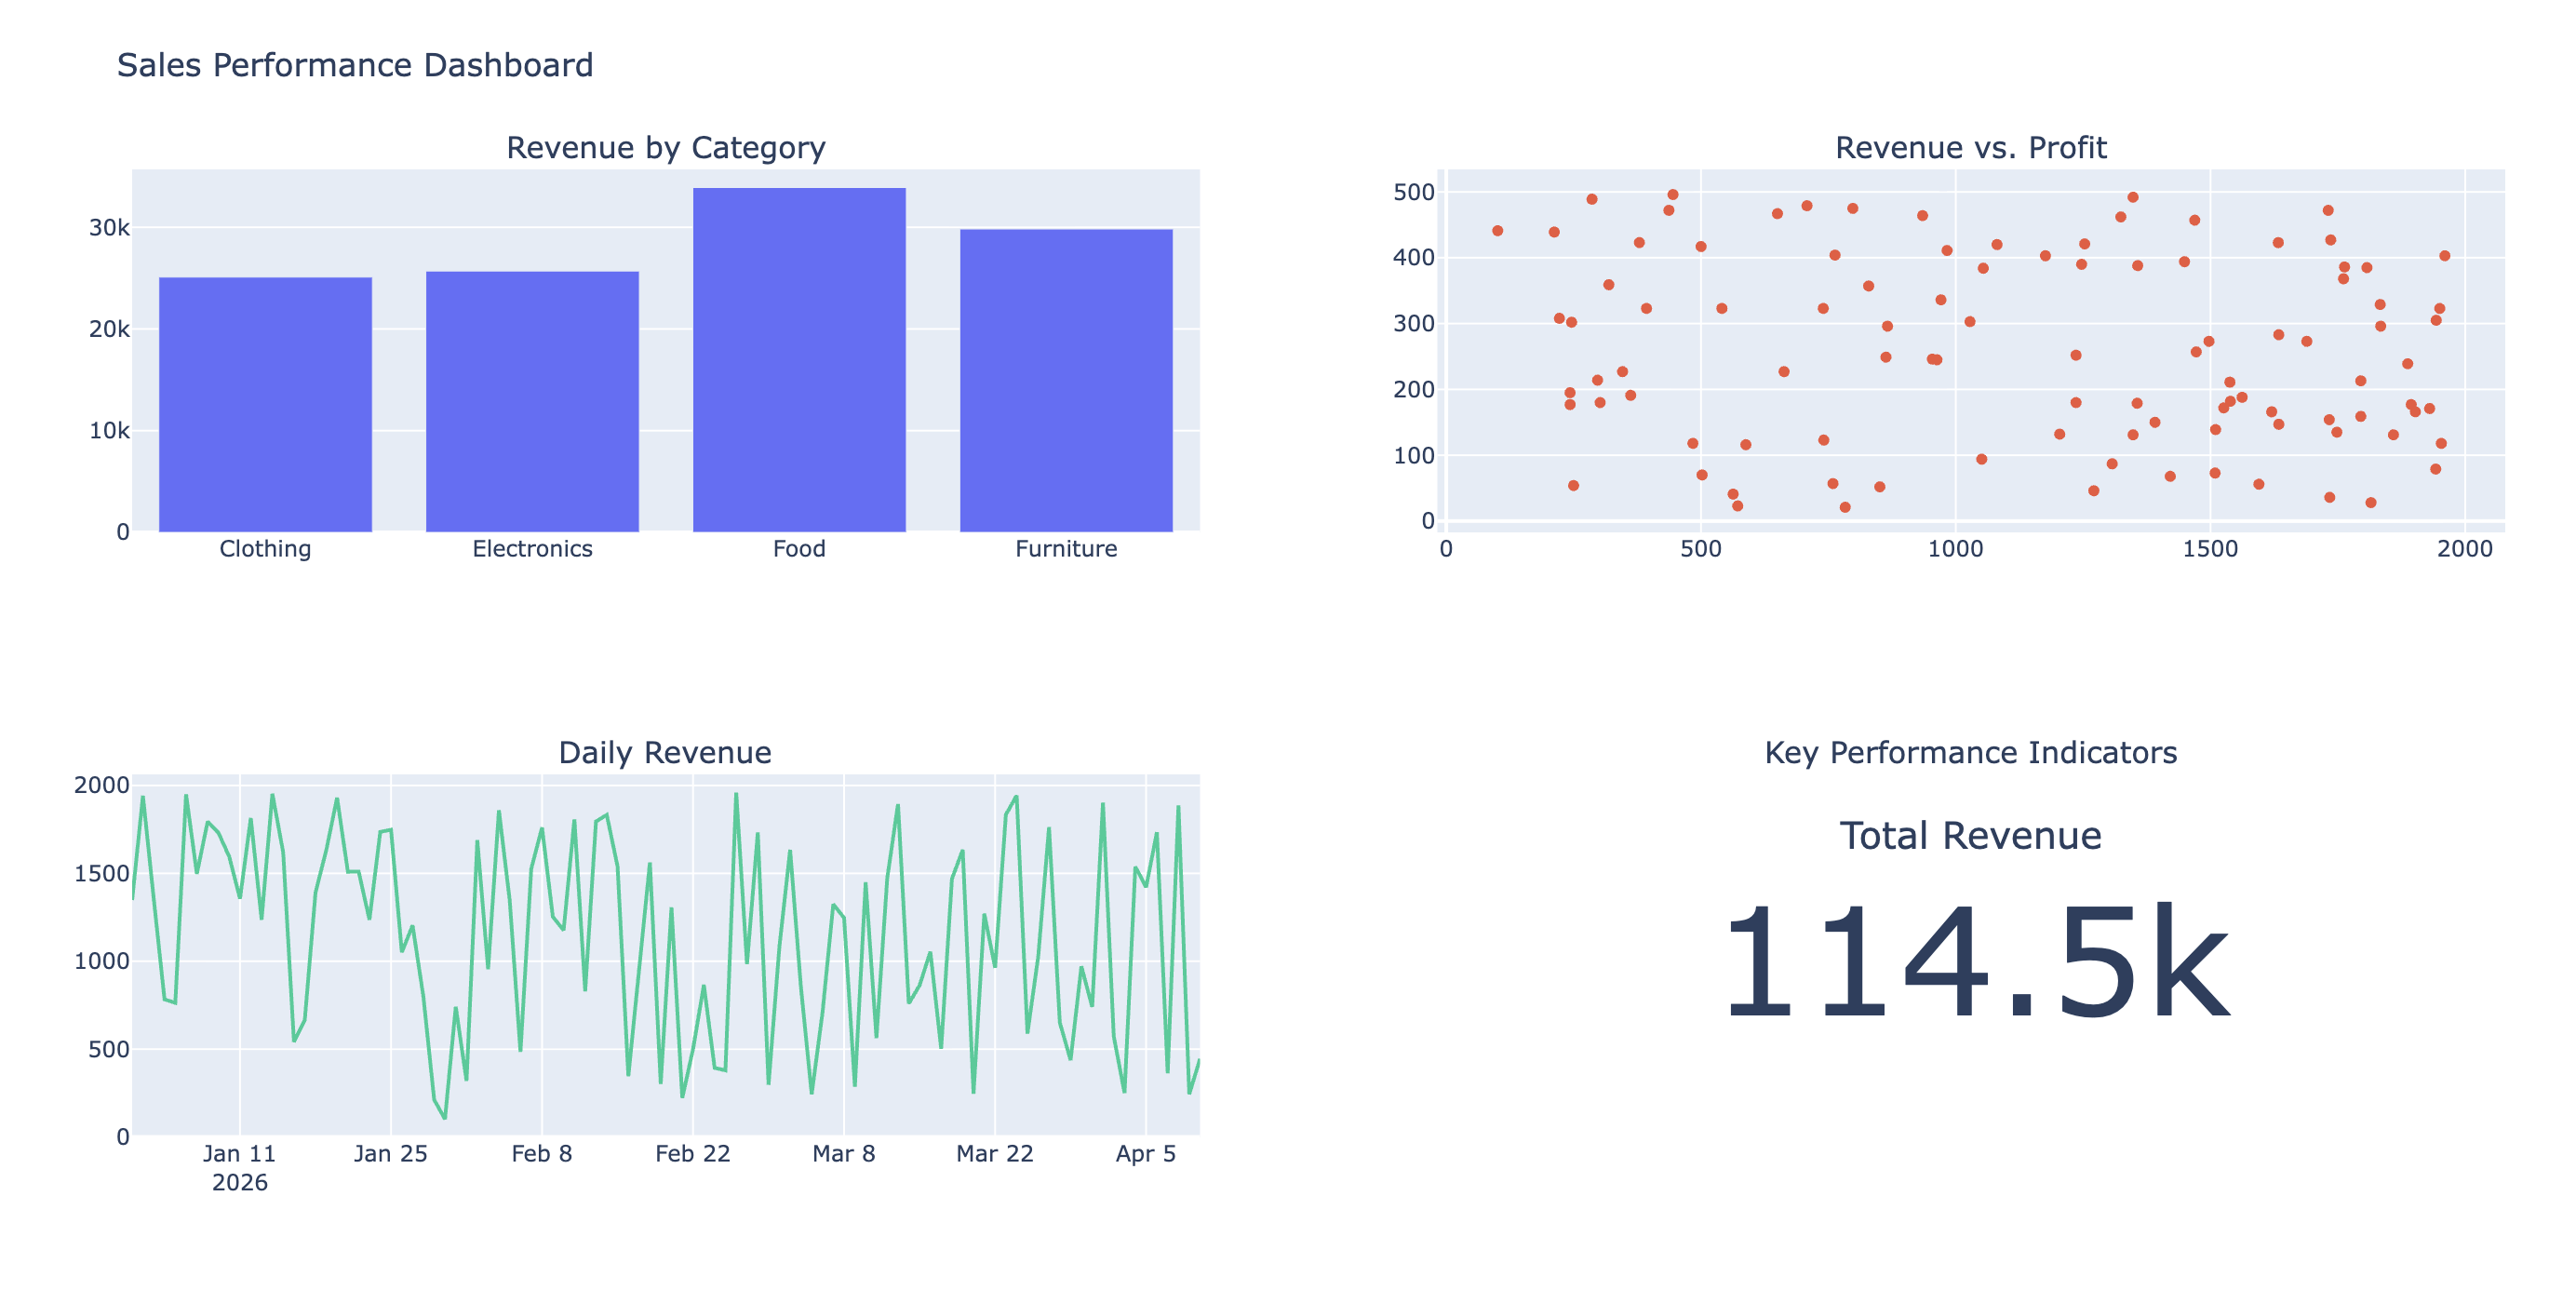

## Gauge Indicator

A gauge chart provides an immediate visual status update against a predefined target. By color-coding thresholds (red for critical, yellow for warning, and green for success), executives can instantly see target margins, current progress, and the exact distance remaining to hit their monthly or quarterly milestones.

In [15]:
total_revenue = df['Revenue'].sum()
target = 100_000

fig = go.Figure(
    go.Indicator(
        mode='gauge+number+delta',
        value=total_revenue,
        title={'text': 'Revenue Target Achievement'},
        delta={
            'reference': target,
            'valueformat': ',.0f'
        },
        number={
            'valueformat': ',.0f'
        },
        gauge={
            'axis': {
                'range': [0, target],
                'tickformat': ',.0f'
            },
            'bar': {
                'color': 'royalblue'
            },
            'steps': [
                {'range': [0, target * 0.5],
                 'color': 'lightgray'},
                {'range': [target * 0.5, target * 0.8],
                 'color': 'lightyellow'},
                {'range': [target * 0.8, target],
                 'color': 'lightgreen'}
            ],
            'threshold': {
                'line': {'color': 'red', 'width': 4},
                'thickness': 0.75,
                'value': target
            }
        }
    )
)

fig.show()

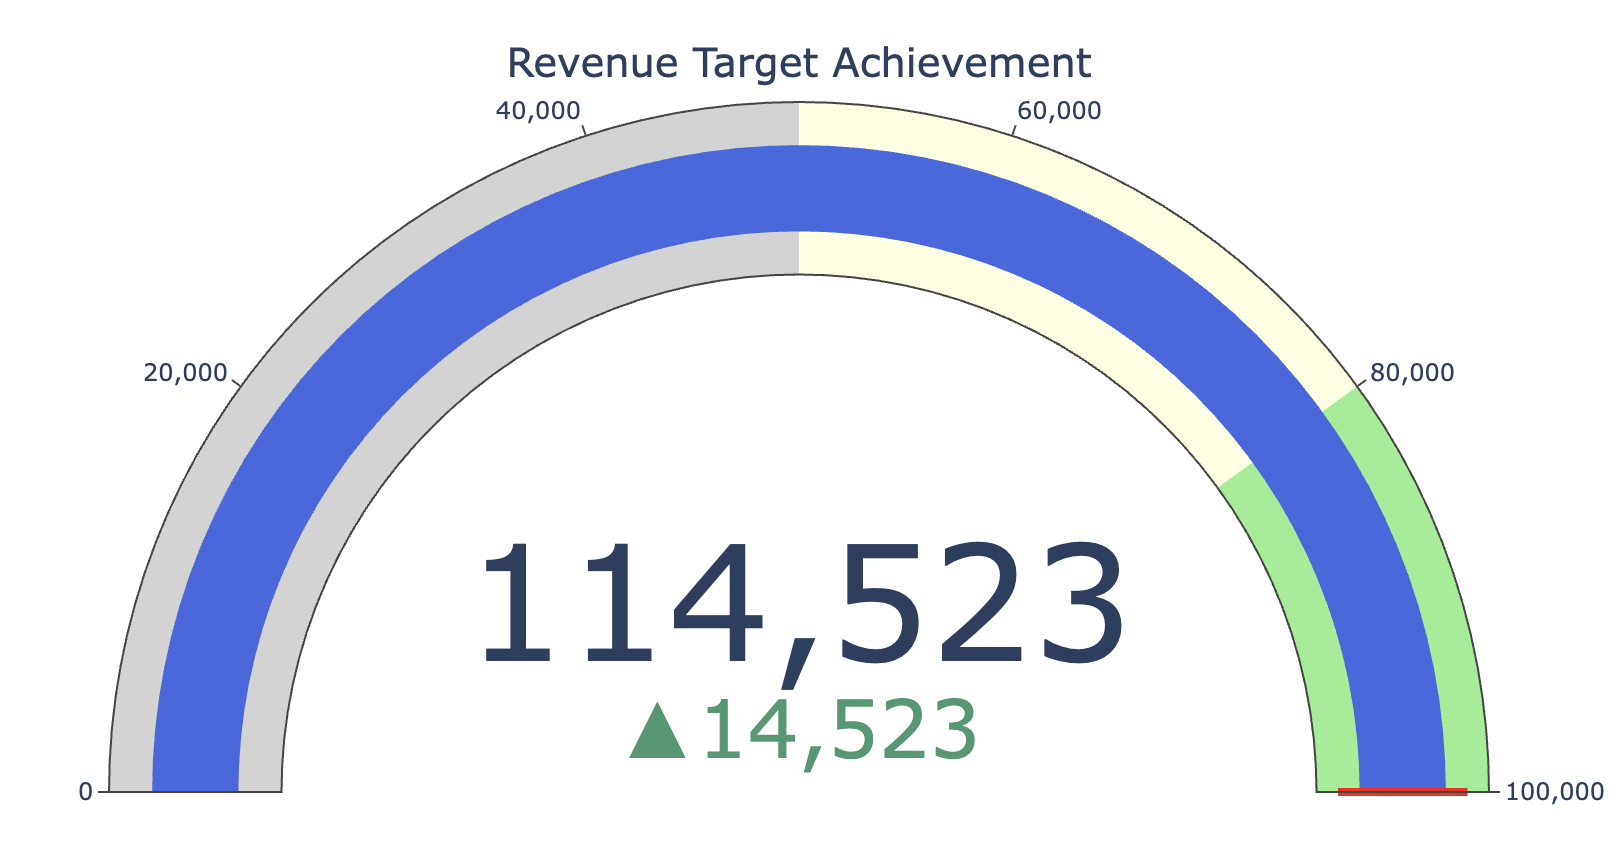

## Other Visualizations

This concluding section showcases advanced and unconventional financial and structural visualizations. We explore **Sunburst Charts** for hierarchical breakdowns, **Horizon Charts** to efficiently display dense time-series deviations, and traditional financial charts like **Candlesticks** and **Renko Bricks** to track price actions and market trends.

In [16]:
# Sunburst Chart: Revenue by Category and Country
sunburst_data = df.groupby(
    ['Category', 'Country'], as_index=False
)['Revenue'].sum()

fig = px.sunburst(
    sunburst_data,
    path=['Category', 'Country'],
    values='Revenue',
    title='Revenue by Category and Country'
)

fig.show()

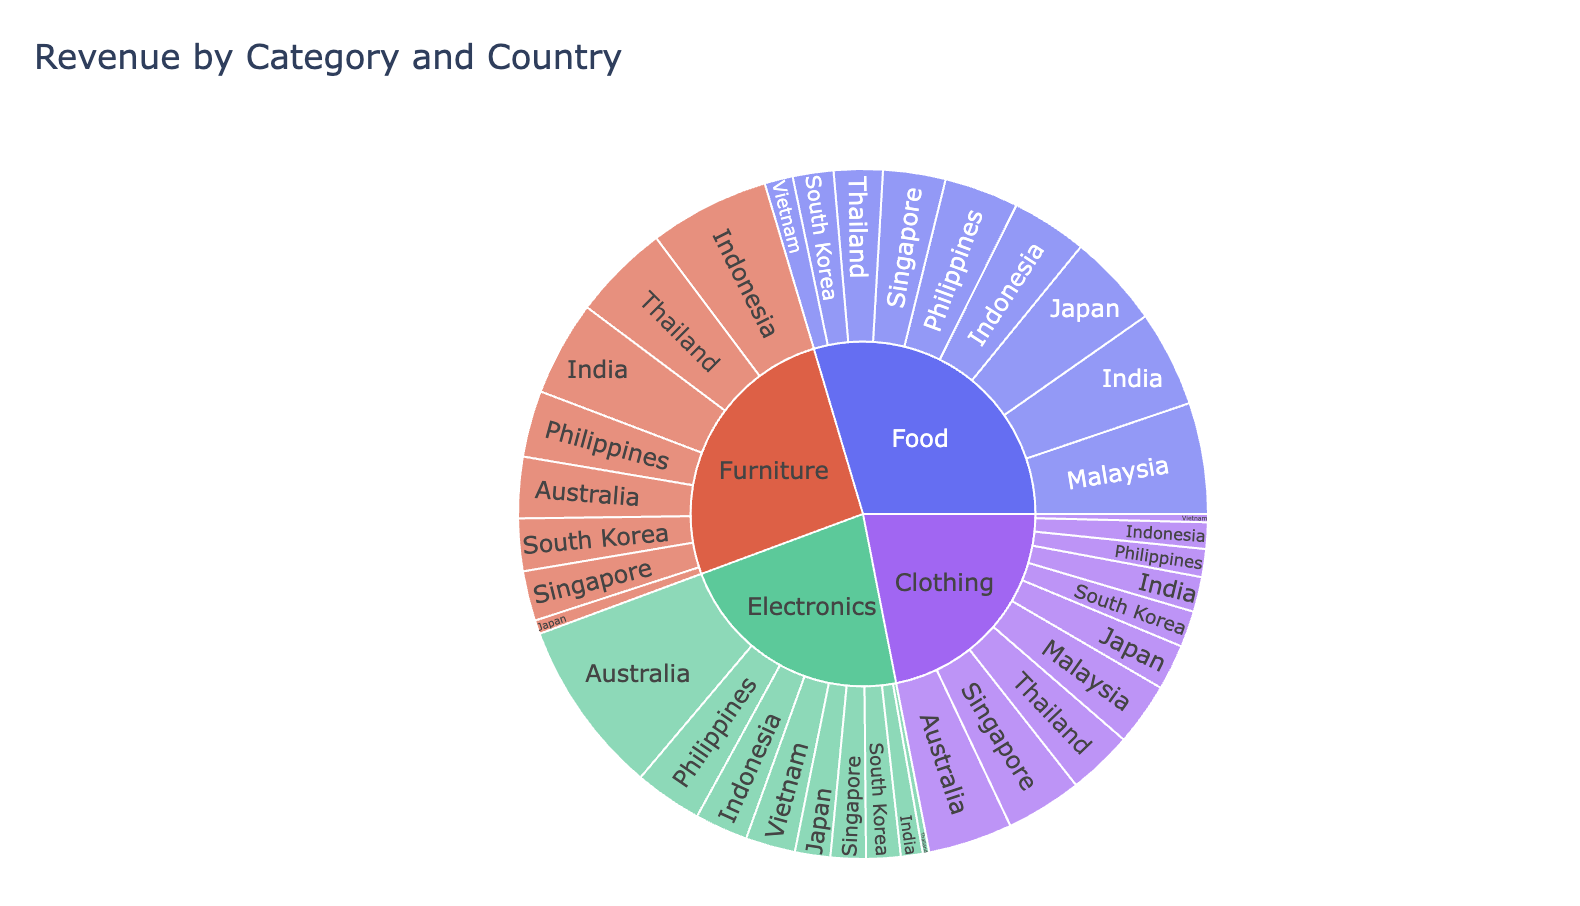

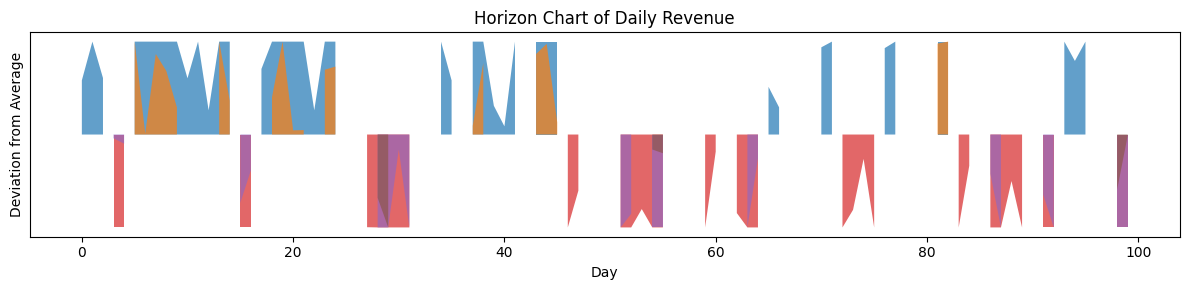

In [17]:
# Horizon Chart: Daily Revenue
daily_revenue = (
    df.groupby('Date')['Revenue']
    .sum()
    .sort_index()
)

# Calculate deviations from the average
values = daily_revenue.values
baseline = daily_revenue.mean()
deviations = values - baseline

# Divide positive and negative deviations into bands
band_width = max(abs(deviations).max() / 3, 1)
x = np.arange(len(values))

fig, ax = plt.subplots(figsize=(12, 3))

# Positive bands
for i in range(3):
    lower = i * band_width
    upper = (i + 1) * band_width

    band = np.clip(
        deviations - lower, 0, band_width
    )

    ax.fill_between(
        x, 0, band,
        where=deviations > lower,
        alpha=0.7
    )

# Negative bands
for i in range(3):
    lower = i * band_width
    upper = (i + 1) * band_width

    band = np.clip(
        -deviations - lower, 0, band_width
    )

    ax.fill_between(
        x, 0, -band,
        where=deviations < -lower,
        alpha=0.7
    )

ax.set_title('Horizon Chart of Daily Revenue')
ax.set_xlabel('Day')
ax.set_ylabel('Deviation from Average')
ax.set_yticks([])
plt.tight_layout()
plt.show()

In [18]:
# Generate 100 samples of financial price data
np.random.seed(42)

dates = pd.bdate_range(
    start='2026-01-01',
    periods=100
)

close_prices = 100 + np.cumsum(
    np.random.normal(0, 2, 100)
)

open_prices = np.concatenate((
    [100],
    close_prices[:-1]
)) + np.random.normal(0, 1, 100)

high_prices = np.maximum(
    open_prices, close_prices
) + np.random.uniform(0.2, 2, 100)

low_prices = np.minimum(
    open_prices, close_prices
) - np.random.uniform(0.2, 2, 100)

stock_df = pd.DataFrame({
    'Date': dates,
    'Open': open_prices,
    'High': high_prices,
    'Low': low_prices,
    'Close': close_prices
})

# Create the Candlestick Chart
fig = go.Figure(data=[
    go.Candlestick(
        x=stock_df['Date'],
        open=stock_df['Open'],
        high=stock_df['High'],
        low=stock_df['Low'],
        close=stock_df['Close']
    )
])

fig.update_layout(
    title='Stock Price Candlestick Chart',
    xaxis_title='Date',
    yaxis_title='Price',
    xaxis_rangeslider_visible=False
)

fig.show()

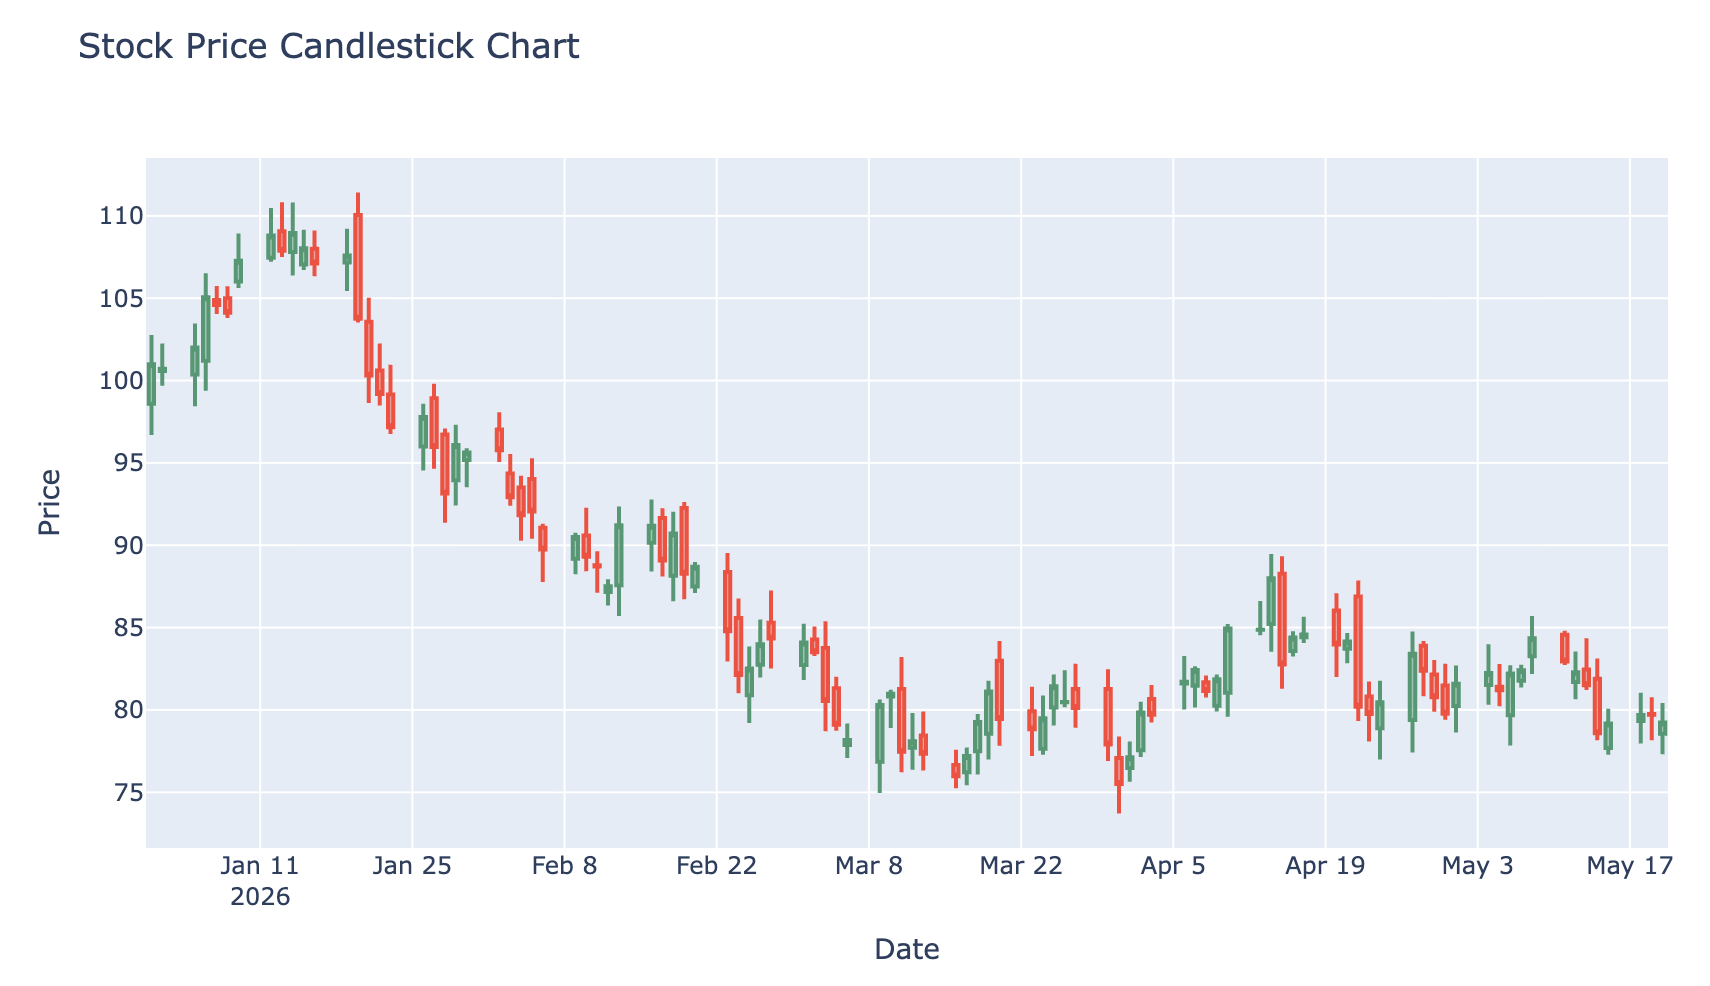

In [21]:
# Build a simplified Renko Chart
brick_size = 2

renko_prices = [stock_df['Close'].iloc[0]]
renko_directions = []

for price in stock_df['Close'].iloc[1:]:
    last_price = renko_prices[-1]
    difference = price - last_price

    # Create bricks for every complete price movement
    while abs(difference) >= brick_size:
        direction = 1 if difference > 0 else -1

        new_price = (
            last_price + direction * brick_size
        )

        renko_prices.append(new_price)
        renko_directions.append(direction)

        last_price = new_price
        difference = price - last_price

renko_df = pd.DataFrame({
    'Brick': range(1, len(renko_prices)),
    'Start': renko_prices[:-1],
    'End': renko_prices[1:],
    'Direction': renko_directions
})

# Draw the Renko bricks
fig = go.Figure()

# Add dummy trace to auto-scale the axes
fig.add_trace(go.Scatter(
    x=[0, len(renko_prices)],
    y=[min(renko_prices) - brick_size, max(renko_prices) + brick_size],
    mode='markers',
    marker=dict(opacity=0),
    showlegend=False
))

for _, row in renko_df.iterrows():
    color = 'green' if row['Direction'] > 0 else 'red'

    fig.add_shape(
        type='rect',
        x0=row['Brick'] - 0.4,
        x1=row['Brick'] + 0.4,
        y0=min(row['Start'], row['End']),
        y1=max(row['Start'], row['End']),
        fillcolor=color,
        line=dict(color=color)
    )

fig.update_layout(
    title='Renko Chart of Closing Prices',
    xaxis_title='Brick Number',
    yaxis_title='Price',
    showlegend=False
)

fig.show()

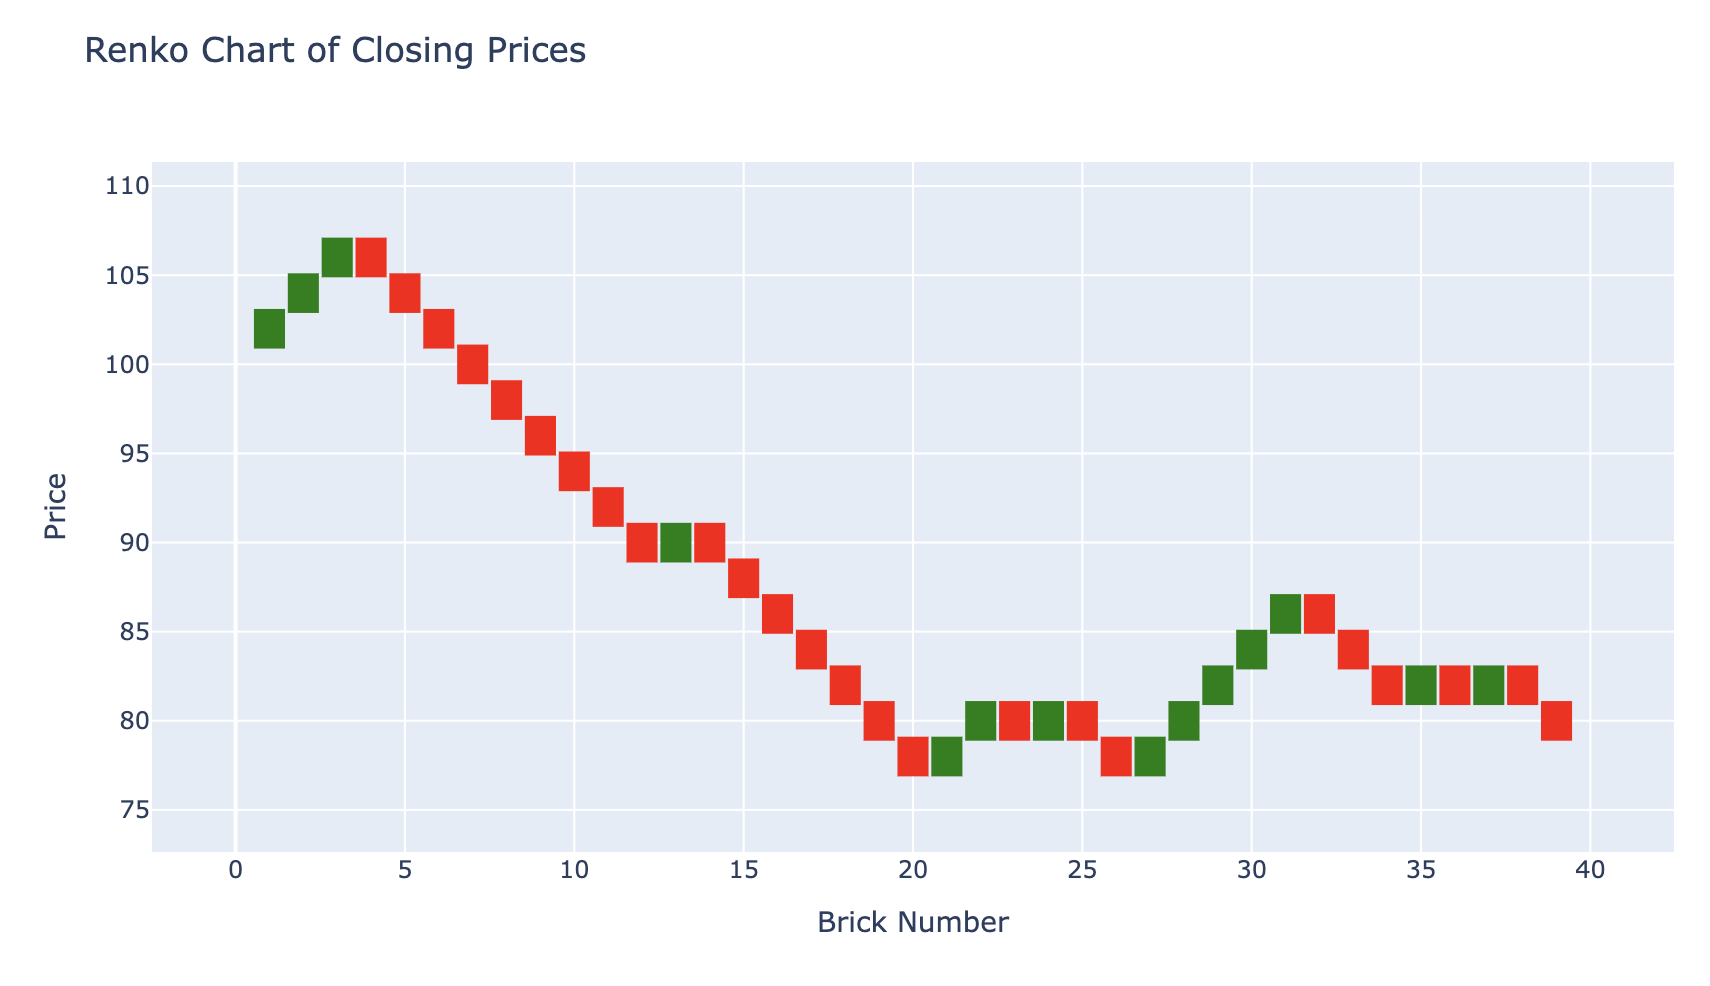